In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE
import requests

today = date.today()

**TSS Coordinates for Genes in Genesets**

In [2]:
datadir = '/home/ctrader/region_similarity/data/'

# geneset paths
hallmark_f =  datadir + 'h.all.v7.5.1.symbols.gmt'
c2_f = datadir + 'c2.all.v7.5.1.symbols.gmt'

# genecode
genecode_f = datadir + 'gencode.v41.basic.annotation.parsed.CT20221007.txt'

In [3]:
# build dictionary of genes mapping to coordinates
# also build dictionary of genes mapping to strand (direction)
f = open(genecode_f)

gene2coords = {}
gene2strand = {}
for line in f.readlines():
    line = line.strip().split('\t')
    if line[4] == 'gene':
        gene = line[3]
#         coord = line[0] + ':' + line[6] + '-' + line[7]  # promoter bp
        coord = [line[0], line[6], line[7]]
        strand = [line[5]]
        if gene not in gene2coords:
#             gene2coords[gene] = np.array([coord])
            gene2coords[gene] = [coord]
            gene2strand[gene] = [strand]
        else:
#             gene2coords[gene] = np.append(gene2coords[gene], np.array([coord]))
            gene2coords[gene].append(coord)
            gene2strand[gene].append(strand)
f.close()

In [4]:
# build dictionary of genesets mapping to a list of genes
geneset2genes = {}
# geneset2description = {}
for gs_f in [hallmark_f, c2_f]:
    f = open(gs_f)
    for line in f.readlines():
        line = line.strip().split('\t')
        gs = line[0]
#         d = line[1]
        genes = line[2:]
        geneset2genes[gs] = genes
#         geneset2description[gs] = d
    f.close()

In [5]:
# build dictionary of genes mapping to a list of genesets
gene2genesets = {}
for gs in geneset2genes.keys():
    genes = geneset2genes[gs]
    for g in genes:
        if g not in gene2genesets:
            gene2genesets[g] = np.array([gs])
        else:
            gene2genesets[g] = np.append(gene2genesets[g], np.array([gs]))

In [6]:
# get the full list of genes
genes_in_gs = []
for gs in list(geneset2genes.keys()):
    genes_in_gs.extend(geneset2genes[gs])
genes_in_gs = np.unique(genes_in_gs)

In [7]:
# get TSS bp coordinates for genes in genesets
genes_in_gs_coords = []

for gene in genes_in_gs:
    if gene in gene2coords:
        coords = gene2coords[gene]
        if ((len(coords) == 1) & 
            (coords[0][0][-1] != 'M') & 
            (len(gene2strand[gene]) == 1)):
            genes_in_gs_coords.append(
                np.append(
                    np.append(
                        coords[0], 
                        gene
                    ), 
                    gene2strand[gene][0]
                )
            )
            
genes_in_gs_coords = np.array(genes_in_gs_coords)

**Assign Basal Regions to Each Gene**

In [8]:
genes_in_gs_coords = np.hstack(
    (
        genes_in_gs_coords, 
        np.zeros((genes_in_gs_coords.shape[0], 2), dtype=str)
    )
)

In [9]:
# define basal region distances
basal_up = 5000
basal_down = 1000

In [10]:
# define basal regions for each gene
for gene in genes_in_gs_coords:
    strand = gene[4]
    if strand == '+':
        gene[5] = str(np.max([0, int(gene[1]) - basal_up]))
        gene[6] = str(int(gene[1]) + basal_down)
    if strand == '-':
        gene[5] = str(np.max([0, int(gene[2]) - basal_down]))
        gene[6] = str(int(gene[2]) + basal_up)

**Sorting genes**

In [11]:
# sort genes by genomic location for easy basal domain extension
ind_order = np.array([], dtype=int)
chrm_order = np.unique(genes_in_gs_coords[:, 0])
for chrm in chrm_order:
    chrm_inds = np.where(genes_in_gs_coords[:, 0] == chrm)[0]
    basal_start_bp = genes_in_gs_coords[chrm_inds, 5].astype(int)
    chrm_inds_ordered = chrm_inds[np.argsort(basal_start_bp)]
    ind_order = np.append(ind_order, chrm_inds_ordered)
    
genes_in_gs_coords = genes_in_gs_coords[ind_order]

**Extending Basal Domain**

In [12]:
genes_in_gs_coords = np.hstack(
    (
        genes_in_gs_coords, 
        np.zeros((genes_in_gs_coords.shape[0], 2), dtype=str)
    )
)

In [13]:
# define extension distance
extension_dist = 1000000

In [14]:
for i in range(len(genes_in_gs_coords)):
    gene = genes_in_gs_coords[i]
    g_chr = gene[0]
    g_basal_start = int(gene[5])
    g_basal_end = int(gene[6])
    
    # find neighboring genes
    if i != 0:
        left_gene = genes_in_gs_coords[i - 1]
    else:
        left_gene = genes_in_gs_coords[-1]
    if i != len(genes_in_gs_coords) - 1:
        right_gene = genes_in_gs_coords[i + 1]
    else:
        right_gene = genes_in_gs_coords[0]
    
    # extend left domain of gene
    if left_gene[0] != g_chr:  # different chromosome
        left_extended = np.max([0, g_basal_start - extension_dist])
    else:  # same chromosome
        left_gene_end = int(left_gene[6])
        left_extended = np.max([
            np.min([left_gene_end, g_basal_start]),
            g_basal_start - extension_dist
        ])
    genes_in_gs_coords[i, 7] = str(left_extended)
    
    # extend right domain of gene
    if right_gene[0] != g_chr:  # different chromosome
        right_extended = g_basal_end + extension_dist
    else:  # same chromosome
        right_gene_start = int(right_gene[5])
        right_extended = np.min([
            np.max([right_gene_start, g_basal_end]),
            g_basal_end + extension_dist
        ])
    genes_in_gs_coords[i, 8] = str(right_extended)    

**Saving**

In [30]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'

In [31]:
# out_f = datadir + 'single_coord_mapping_genes_in_h_c2_gs.TSS_bp.gene.strand.basal_5kbup_1kbdown.extended_1000kb.gencode.v41.CT20230523.bed'
# np.savetxt(out_f, genes_in_gs_coords, fmt='%s', delimiter='\t')

In [32]:
# out_f = datadir + 'single_coord_mapping_genes_in_h_c2_gs.extended_domain_1000kb.gene.gencode.v41.CT20230523.bed'
# np.savetxt(out_f, genes_in_gs_coords[:, [0, 7, 8, 3]], fmt='%s', delimiter='\t')

**Generate bed file from search spaces**

In [47]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'

In [48]:
scale = '25'
search_space_file = datadir + 'regions_' + scale + 'kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'


search_space_coords = np.load(search_space_file)['coordinates']
search_space_ori_inds = np.load(search_space_file)['original_inds']

In [49]:
search_space_out = np.hstack((search_space_coords, search_space_ori_inds.reshape(-1, 1)))

In [50]:
# search_space_out_file = datadir + 'regions_' + scale + 'kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.bed'

# np.savetxt(search_space_out_file, search_space_out, fmt='%s', delimiter='\t')

In [53]:
# sort and map
"""
sort-bed regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.bed > regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.bed
bedmap --echo --echo-map-id regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.bed single_coord_mapping_genes_in_h_c2_gs.extended_domain_1000kb.gene.gencode.v41.CT20230523.sorted.bed > regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.h_c2_gs_genes_extended_domain_1000kb_mapped.bed
"""

**Parse mapped file and populate binary matrix**

In [82]:
gene_order = genes_in_gs_coords[:, 3]

In [206]:
geneset_order = np.array(list(geneset2genes.keys()))

In [231]:
# create a binary geneset x gene array
geneset_gene_bin = np.zeros((len(geneset_order), len(gene_order)), dtype=int)

for i in range(len(geneset_order)):
    gs = geneset_order[i]
    genes = geneset2genes[gs]
    
    # find ordered gene inds
    gs_genes_inds = np.where(np.isin(gene_order, genes))[0]
    
    # set genes in gs to 1
    geneset_gene_bin[i, gs_genes_inds] = 1

In [238]:
gsxg_bin_f = datadir + 'single_coord_mapping_genes_in_h_c2_gs.gsXgene.bin.CT20230524.npz'

x = sp.sparse.coo_matrix(geneset_gene_bin)
sp.sparse.save_npz(gsxg_bin_f, x)

In [256]:
gsxg_bin_f = datadir + 'single_coord_mapping_genes_in_h_c2_gs.gsXgene.bin.CT20230524.npz'
geneset_gene_coo = sp.sparse.load_npz(gsxg_bin_f)

In [89]:
mapped_f = datadir + 'regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.h_c2_gs_genes_extended_domain_1000kb_mapped.bed'

f = open(mapped_f)
lines = f.readlines()
f.close()

# binary matrix for genes located in each search space region
search_space_gene_bin = np.zeros((len(lines), len(gene_order)), dtype=int)

# for each search space region, populate binary matrix
for i in range(len(lines)):
    line = lines[i]
    line = re.split('[\t|;]', line.strip())
    mapped_genes = line[4:]
    for gene in mapped_genes:
        if gene != '':
            search_space_gene_bin[i, np.where(gene_order == gene)[0][0]] = 1

In [125]:
# bin_f = datadir + 'regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.h_c2_gs_genes_extended_domain_1000kb_mapped.bin.npz'

# x = sp.sparse.coo_matrix(search_space_gene_bin)
# sp.sparse.save_npz(bin_f, x)

In [147]:
bin_f = datadir + 'regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.h_c2_gs_genes_extended_domain_1000kb_mapped.bin.npz'

search_space_gene_coo = sp.sparse.load_npz(bin_f)

In [672]:
"""
Take in an array that contains the genes nearby each search space 
region and a list of search space indices. Returns the counts of each
gene for set search space regions. 
"""
def searchspace2genes(search_space_gene_coo, search_space_inds):
    # spare region and gene data
    ssg_regions = search_space_gene_coo.row
    ssg_genes = search_space_gene_coo.col
    
    # find genes for search space regions
    ssg_ssregioninds = np.where(np.isin(ssg_regions, search_space_inds))[0]
    ssg_ssgeneinds = ssg_genes[ssg_ssregioninds]
#     print(np.unique(gene_order[ssg_ssgeneinds]))
    
    return ssg_ssgeneinds, np.unique(gene_order[ssg_ssgeneinds])

"""
Take in a sparse array that contains the genes nearby each search space 
region, a sparse array that contains the genes for each geneset, and 
a list of search space indices. For each geneset, a fisher's exact test
is done to determine significance for any of the search space region genes.
A list of genesets and their significance value (pvalue?) is returned.
"""
def searchspace_geneset_enrichment(search_space_gene_coo, geneset_gene_coo, search_space_inds):
    gsg_gs = geneset_gene_coo.row
    gsg_genes = geneset_gene_coo.col
    
    # get the gene inds for set of search space regions
    ss_geneinds, genes_out = searchspace2genes(search_space_gene_coo, search_space_inds)
    ss_geneinds = np.unique(ss_geneinds)
    # inds for all genes
    all_geneinds = np.arange(len(gene_order))

    pvals = []
    genes_out_ss_gs = []
    # for each geneset, test for significance
    for gs in range(len(geneset_order)):
        # find sparse inds for geneset
        gs_inds = np.where(gsg_gs == gs)[0]
        # find corresponding gene inds
        gs_geneinds = gsg_genes[gs_inds]
        # find inds for genes not in geneset
        notgs_geneinds = all_geneinds[~np.isin(all_geneinds, gs_geneinds)]

        # find genes in (or not) geneset and search space
        genes_ss_gs = gs_geneinds[np.isin(gs_geneinds, ss_geneinds)]
        genes_out_ss_gs.append(genes_ss_gs)
        genes_notss_gs = gs_geneinds[~np.isin(gs_geneinds, ss_geneinds)]
        genes_ss_notgs = notgs_geneinds[np.isin(notgs_geneinds, ss_geneinds)]
        genes_notss_notgs = notgs_geneinds[~np.isin(notgs_geneinds, ss_geneinds)]

        # test for significance
        contingency_table = [
            [len(genes_ss_gs), len(genes_notss_gs)],
            [len(genes_ss_notgs), len(genes_notss_notgs)]
        ]
        odds, pval = fisher_exact(contingency_table, alternative='greater')
        # bonferroni correction
        pvals.append(pval * len(geneset_order))
    pvals = np.array(pvals)

    
    # sort by pvals
    pvals = np.where(pvals > 1, 1, pvals)
    sort_order = np.argsort(pvals)
    return geneset_order[sort_order], pvals[sort_order], genes_out, np.array(genes_out_ss_gs, dtype=object)[sort_order]

In [625]:
geneset_gene_bin.shape

(6416, 21486)

In [626]:
# gs_i = 6000
# print(geneset_order[gs_i])
# search_space_inds = np.argsort(-np.sum(search_space_gene_bin[:, np.where(geneset_gene_bin[gs_i])[0]], axis=1))[:20]

In [627]:
# search_space_inds = np.random.randint(0, 32746, 20)

In [455]:
sig_gs, sig_pvals = searchspace_geneset_enrichment(search_space_gene_coo, geneset_gene_coo, search_space_inds)

In [456]:
for i, j in zip(sig_gs, sig_pvals[:10]):
    print(i, j)

BIOCARTA_PLATELETAPP_PATHWAY 6.235864003260205e-21
BIOCARTA_INTRINSIC_PATHWAY 1.2848910942762497e-12
BIOCARTA_AMI_PATHWAY 2.4266830511899887e-10
WP_BLOOD_CLOTTING_CASCADE 2.374142528107888e-07
REACTOME_ECM_PROTEOGLYCANS 1.3146898599098034e-06
BIOCARTA_NPP1_PATHWAY 1.6055437374676747e-06
BIOCARTA_VITCB_PATHWAY 2.521118062177182e-06
REACTOME_EXTRACELLULAR_MATRIX_ORGANIZATION 5.2509830603904985e-06
BIOCARTA_ACE2_PATHWAY 5.454288099035046e-06
REACTOME_ANCHORING_FIBRIL_FORMATION 1.0397225463266305e-05


In [661]:
dl = 2
query_coords = 'chr1:99642000-99667000' # no results from great
query_coords = 'chr17:61886000-61911000'
scale = 25

response = production_post_request(query_coords, scale)
query_full_data = json.loads(response.text)

query_sim_region_inds = []
query_sim_region_coords = []
for i in range(1, 101):
    coord = re.split('[:-]', query_full_data[dl - 1][i]['coordinates'])
    query_sim_region_coords.append(coord)
    query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])

In [675]:
# for coord in query_sim_region_coords:
#     print(coord[0] + '\t' + coord[1] + '\t' + coord[2])

In [676]:
# for i in query_sig_gs[:10]:
#     print(i)

In [673]:
query_sig_gs, query_sig_pvals, genes_out, selected_genes_out = searchspace_geneset_enrichment(search_space_gene_coo, geneset_gene_coo, query_sim_region_inds)
# for i, j, g in zip(query_sig_gs, query_sig_pvals[:10], selected_genes_out):
#     print(i, j, gene_order[g])

In [674]:
# best_genes = []
# for i in range(10):
#     best_genes.extend(selected_genes_out[i])
# best_genes, best_genes_counts = np.unique(best_genes, return_counts=True)
# order = np.argsort(-best_genes_counts)
# for o in order:
#     print(gene_order[best_genes][o])

In [671]:
# for gs in geneset_order:
#     print('curl "https://www.gsea-msigdb.org/gsea/msigdb/human/download_geneset.jsp?geneSetName=' + gs + '&fileType=TSV" > ' + gs + '.tsv')

**Parse mapped file and populate binary Geneset x Region matrix**

In [15]:
gene_order = genes_in_gs_coords[:, 3]
geneset_order = np.array(list(geneset2genes.keys()))

In [16]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
mapped_f = datadir + 'regions_25kb_CT20230523.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.h_c2_gs_genes_extended_domain_1000kb_mapped.bed'

f = open(mapped_f)
lines = f.readlines()
f.close()

# binary matrix for genes located in each search space region
search_space_geneset_bin = np.zeros((len(lines), len(geneset_order)), dtype=int)

# for each search space region, populate binary matrix
for i in range(len(lines)):
    line = lines[i]
    line = re.split('[\t|;]', line.strip())
    mapped_genes = line[4:]
    
    mapped_gene_genesets = np.array([])
    for g in mapped_genes:
        if g != '':
            mapped_gene_genesets = np.append(mapped_gene_genesets, gene2genesets[g])
    mapped_gene_genesets = np.unique(mapped_gene_genesets)

    gs_inds = np.where(np.isin(geneset_order, mapped_gene_genesets))[0]
    
    search_space_geneset_bin[i, gs_inds] = 1

In [17]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
out_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_gene_h_c2_genesets.bin.CT20230531.npy'

np.save(out_f, search_space_geneset_bin)

Get query regions

In [22]:
def production_post_request(coords, scale):
    prod_url = 'https://explore.altius.org:5001/narration'
    post_body = {
        'location': coords,
        'factors': '[' + ','.join(np.arange(34).astype(str)) + ']',
        'roiURL': 'False',
        'scale': scale,
        'queryFactorThresh': '0.5',
        'numSimilarRegions': '100'
    }
    response = requests.post(prod_url, json=post_body)
    return response

def query_sim_hypergeom(region_inds, N=20, M=num_regions, n=gs_region_counts, geneset_order=geneset_order):
    k = np.sum(search_space_geneset_bin[region_inds], axis=0)
    inds_to_test = np.where(k)[0]
    
    test = hypergeom.sf(k[inds_to_test], M, n[inds_to_test], N)
    tested_genesets = geneset_order[inds_to_test]
    return tested_genesets, test

In [24]:
gs_region_counts = np.sum(search_space_geneset_bin, axis=0)
num_regions = search_space_geneset_bin.shape[0]

In [64]:
dl = 1

query_coords = 'chr10:100141000-100166000' # pretty good, dl=1
query_coords = 'chr4:173514000-173539000' # good at dl=7
query_coords = 'chr14:28755875-28780934' # decent at dl=3, dl=5
query_coords = 'chr2:88112000-88137000' # great at dl=1
scale = 25

response = production_post_request(query_coords, scale)
query_full_data = json.loads(response.text)

query_sim_region_inds = []
query_sim_region_coords = []
for i in range(1, len(query_full_data[0])):
    coord = re.split('[:-]', query_full_data[dl - 1][i]['coordinates'])
    query_sim_region_coords.append(coord)
    query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])

In [65]:
for c in query_sim_region_coords:
    print(c[0] + '\t' + c[1] + '\t' + c[2])

chr8	94187000	94212000
chr4	68859000	68884000
chr16	52554000	52579000
chr17	35980000	36005000
chr12	71139000	71164000
chr9	101421000	101446000
chr11	75149000	75174000
chr13	109570000	109595000
chr5	69436000	69461000
chr2	109061000	109086000
chr11	116808000	116833000
chr20	44434000	44459000
chr17	16289000	16314000
chr10	127881000	127906000
chr1	57308000	57333000
chr8	52379000	52404000
chr20	62412000	62437000
chr13	27957000	27982000
chr14	102866000	102891000
chr20	32212000	32237000
chr21	41497000	41522000
chr3	171660000	171685000
chr17	40881000	40906000
chr5	160634000	160659000
chr20	44346000	44371000
chr9	68718000	68743000
chr11	129410000	129435000
chr22	46190000	46215000
chr12	115458000	115483000
chr13	73062000	73087000
chr3	124623000	124648000
chr3	119780000	119805000
chr16	88485000	88510000
chr6	106038000	106063000
chr12	22583000	22608000
chr1	15180000	15205000
chr22	48269000	48294000
chr17	47950000	47975000
chr5	147163000	147188000
chr19	51474000	51499000
chr8	123735000	123760000
ch

In [66]:
query_tested_gs, query_tested_gs_pval = query_sim_hypergeom(query_sim_region_inds, N=100)

In [76]:
c = 0
sort_order = np.argsort(query_tested_gs_pval)
for i, j in zip(query_tested_gs[sort_order], query_tested_gs_pval[sort_order]):
    if (j * 1000) < 0.05:
        print(i + '\t' + str(j))
        c += 1

VECCHI_GASTRIC_CANCER_ADVANCED_VS_EARLY_DN	2.9828895834547326e-15
SERVITJA_ISLET_HNF1A_TARGETS_DN	1.868243972563555e-09
KIM_LIVER_CANCER_POOR_SURVIVAL_DN	1.1515557610527683e-08
PID_HNF3B_PATHWAY	2.261974432897474e-08
YAMASHITA_LIVER_CANCER_STEM_CELL_DN	1.0359997784988448e-07
WOO_LIVER_CANCER_RECURRENCE_DN	2.336796782500189e-07
ZHOU_PANCREATIC_BETA_CELL	2.6876096586137384e-07
KEGG_MATURITY_ONSET_DIABETES_OF_THE_YOUNG	2.839492998319653e-07
REACTOME_ATTACHMENT_AND_ENTRY	3.0620701653895464e-07
WP_SARSCOV2_AND_ACE2_RECEPTOR_MOLECULAR_MECHANISMS	5.738387998595331e-07
WP_SARSCOV2_AND_COVID19_PATHWAY	6.130149975385698e-07
GOUYER_TATI_TARGETS_UP	7.395429392981693e-07
DESERT_PERIPORTAL_HEPATOCELLULAR_CARCINOMA_SUBCLASS_UP	9.207465693775069e-07
REACTOME_REGULATION_OF_GENE_EXPRESSION_IN_BETA_CELLS	9.8112652844459e-07
MIKI_COEXPRESSED_WITH_CYP19A1	1.5837620699893505e-06
BLANCO_MELO_BRONCHIAL_EPITHELIAL_CELLS_INFLUENZA_A_INFECTION_DN	2.249504845255119e-06
ANDERSEN_CHOLANGIOCARCINOMA_CLASS2	3.1659081

In [73]:
print(c)

1075


**Clustering Matrix**

In [24]:
search_space_geneset_bin.T.shape

(6416, 32749)

In [25]:
# clustering genesets
clustering_method='jaccard'

geneset_search_space_bin_jac = pdist(search_space_geneset_bin.T, metric=clustering_method)
geneset_search_space_z_cluster = hierarchy.average(geneset_search_space_bin_jac)
geneset_search_space_z_cluster_opt = hierarchy.optimal_leaf_ordering(geneset_search_space_z_cluster, geneset_search_space_bin_jac)

geneset_search_space_z_cluster_opt_leaves = hierarchy.leaves_list(geneset_search_space_z_cluster_opt)
# genesets_ordered_norm = genesets[leaves_norm]

In [26]:
print(geneset_search_space_bin_jac.shape,
      geneset_search_space_z_cluster.shape, 
      geneset_search_space_z_cluster_opt.shape, 
      geneset_search_space_z_cluster_opt_leaves.shape)

(20579320,) (6415, 4) (6415, 4) (6416,)


In [30]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_gene_h_c2_genesets.bin.geneset_jac_ave_clusters.CT20230530.npz'

# np.savez(out_f, 
#          geneset_search_space_bin_jac=geneset_search_space_bin_jac, 
#          geneset_search_space_z_cluster=geneset_search_space_z_cluster,
#          geneset_search_space_z_cluster_opt=geneset_search_space_z_cluster_opt,
#          geneset_search_space_z_cluster_opt_leaves=geneset_search_space_z_cluster_opt_leaves)

In [77]:
# clustering_method='jaccard'
# search_space_geneset_bin_jac = pdist(search_space_geneset_bin, metric=clustering_method)
# search_space_geneset_z_cluster = hierarchy.average(search_space_geneset_bin_jac)
# search_space_geneset_z_cluster_opt = hierarchy.optimal_leaf_ordering(search_space_geneset_z_cluster, search_space_geneset_bin_jac)

# search_space_geneset_z_cluster_opt_leaves = hierarchy.leaves_list(search_space_geneset_z_cluster_opt)

In [ ]:
print(search_space_geneset_bin_jac.shape,
      search_space_geneset_z_cluster.shape,
      search_space_geneset_z_cluster_opt.shape,
      search_space_geneset_z_cluster_opt_leaves.shape)

In [ ]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
out_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_gene_h_c2_genesets.bin.regions_jac_ave_clusters.CT20230530.npz'

np.savez(out_f, 
         search_space_geneset_bin_jac=search_space_geneset_bin_jac, 
         search_space_geneset_z_cluster=search_space_geneset_z_cluster,
         search_space_geneset_z_cluster_opt=search_space_geneset_z_cluster_opt,
         search_space_geneset_z_cluster_opt_leaves=search_space_geneset_z_cluster_opt_leaves)

TypeError: not all arguments converted during string formatting

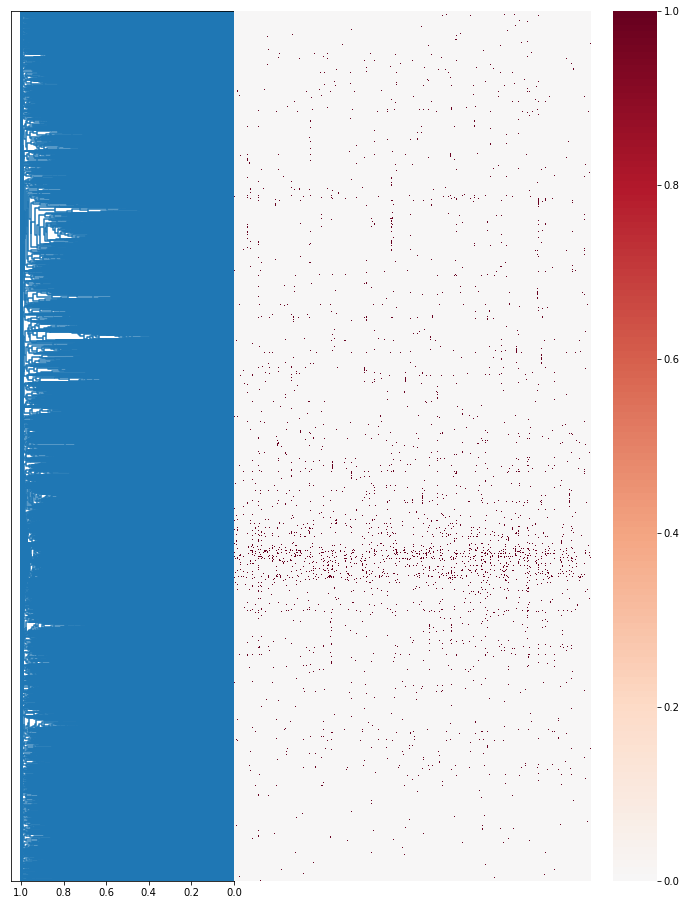

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(z_cluster_opt, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')
# axes[0].set_xticks([])

# have to flip leaves to match dendrogram
sns.heatmap(search_space_geneset_bin.T[np.flip(leaves_norm)], ax=axes[1], cmap='RdBu_r', center=0, vmax=np.max(search_space_geneset_bin), vmin=np.min(search_space_geneset_bin))
axes[1].set_yticks([])

axes[1].set_xticks([])

fig.suptitle('' %clustering_method, y=0.9)

In [ ]:
search_space_geneset_bin_rcordered = search_space_geneset_bin[
        search_space_geneset_z_cluster_opt_leaves # clustered genesets
    ][
        :, np.flip(geneset_search_space_z_cluster_opt_leaves) # clustered regions
    ]

In [2]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_gene_h_c2_genesets.bin.CT20230531.npy'
search_space_geneset_bin = np.load(in_f)

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_gene_h_c2_genesets.bin.geneset_jac_ave_clusters.CT20230530.npz'
         
geneset_search_space_bin_jac = np.load(in_f)['geneset_search_space_bin_jac']
geneset_search_space_z_cluster = np.load(in_f)['geneset_search_space_z_cluster']
geneset_search_space_z_cluster_opt = np.load(in_f)['geneset_search_space_z_cluster_opt']
geneset_search_space_z_cluster_opt_leaves = np.load(in_f)['geneset_search_space_z_cluster_opt_leaves']

In [4]:
search_space_geneset_bin_cordered = search_space_geneset_bin[:, geneset_search_space_z_cluster_opt_leaves]
search_space_geneset_bin_cordered.shape, geneset_search_space_z_cluster_opt_leaves.shape

((32749, 6416), (6416,))

In [5]:
clustering_method = 'jaccard'

Text(0.5, 0.9, '25kb Region-Geneset Binary Matrix Clustered by Genesets with average jaccard clustering')

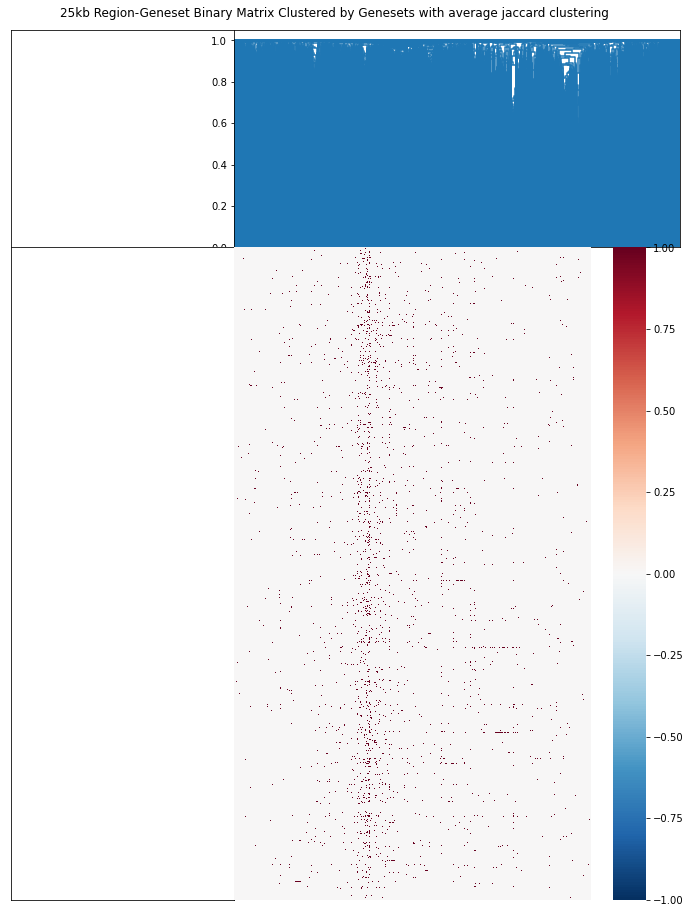

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2], 'height_ratios': [1, 3]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0, hspace=0)

axes.ravel()
d = hierarchy.dendrogram(geneset_search_space_z_cluster_opt, ax=axes[0, 1], no_labels=True, color_threshold=0, orientation='top')

sns.heatmap(
    search_space_geneset_bin_cordered, 
    ax=axes[1, 1], 
    cmap='RdBu_r', 
    center=0, 
    vmax=1, 
    vmin=-1
)
axes[1, 1].set_yticks([])
axes[1, 1].set_xticks([])
axes[0, 0].set_yticks([])
axes[0, 0].set_xticks([])
axes[1, 0].set_yticks([])
axes[1, 0].set_xticks([])

fig.suptitle('25kb Region-Geneset Binary Matrix Clustered by Genesets with average %s clustering' %clustering_method, y=0.9)

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(12, 16))
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0, hspace=0)

sns.heatmap(
    search_space_geneset_bin_cordered, 
    ax=axes, 
    cmap='RdBu_r', 
    center=0, 
    vmax=1, 
    vmin=0
)

axes.set_xlabel('Genesets')
axes.set_ylabel('Search Space Regions')

fig.suptitle('25kb Region-Geneset Binary Matrix Clustered by Genesets with average %s clustering' %clustering_method, y=0.9)